# <font color="#0b486b">FIT3181 | FIT5215: Deep Learning (2026)</font>
***

*CE/Lecturer (Clayton):* **Dr [Trung Le](mailto:trunglm@monash.edu)** <br/>
*Lecturer (Clayton):* **Dr [Binh Nguyen](mailto:binh.nguyen1@monash.edu)** <br/>
*Lecturer (Malaysia):*  **Dr [Arghya Pal](mailto:arghya.pal@monash.edu)**, **Dr [Sailaja Rajanala](mailto:sailaja.rajanala@monash.edu)**, **Dr [Sicily Fung Fung Ting](mailto:ting.fung@monash.edu)** <br/>
*Head Tutor (Clayton):* **Mr [Minh Vo](mailto:minh.vo1@monash.edu)** (FIT3181), **Dr [Ruda Nie H](mailto:rudanie.h@monash.edu)** (FIT5215)<br/> <br/>

Faculty of Information Technology, Monash University, Australia
***

# <font color="#0b486b">Tutorial 06c: Visualization of Filters and Feature Maps of CNNs</font> <font color="red">***</font> #
This is an **encourage-to-learn** knowledge since visualizing what is learned by CNNs is an important practical skill for taming and insightfully understanding the operation of CNNs.

**The purpose of this tutorial is to assist you in mastering the techniques used to visualize filters and feature maps of CNNs. This skill is very crucial to understand insightfully how CNNs work and diagnose when your CNNs work and do not work. The following topics will be covered in this tutorial:**

I. Visualize the raw filters and feature maps of CNNs.

II. Visualize the filters of CNNs using activation maximization.

III. Visualize the filters of CNNs using activation maximization with the `pytorch-grad-cam` library.

IV. Visualize the model explanation using the GradCam technique.

**References and additional reading and resources**
- Understanding Neural Networks Through Deep Visualization, ICML 2015 ([link](https://arxiv.org/pdf/1506.06579)).
- The Github of `pytorch-grad-cam` ([link](https://github.com/jacobgil/pytorch-grad-cam)).
- The Github of implementation of grad-cam ([link](https://github.com/kazuto1011/grad-cam-pytorch.git)).
- Models and pre-trained weights ([link](https://pytorch.org/vision/0.8/models.html)).
- VGG16 Neural Network Visualization ([link](https://www.youtube.com/watch?v=RNnKtNrsrmg)).

---


### <font color="#0b486b"> II.0 Running on Google Colab</font> <font color="red"></font>
To run this notebook on Google Colab, ensure you download the necessary files.

In [ ]:
# install gdown and download data for the first time
!pip install gdown
import gdown
gdown.download_folder(id="1DZCJUTWmj9ltxIZUnV_1Gc5U4Lc2kxY3", output=".", quiet=True)

['./imgs/BottleneckResidualBlock.png',
 './imgs/cat.jpg',
 './imgs/chicken.jpeg',
 './imgs/dog-and-cat.jpg',
 './imgs/elephant.jpg',
 './imgs/ResidualBlock.png',
 './imgs/spider.jpg',
 './labels/imagenet_class_index.json']

In [ ]:
#!unzip -q Tut06_data.zip

## <font color="#0b486b">I. Visualize Filters and Feature Maps a Pretrained Network</font> ##

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.autograd import Variable
from collections.abc import Sequence

import numpy as np
from torch.nn import functional as F
from tqdm import tqdm
import matplotlib.cm as cm
import matplotlib.pyplot as plt
from torchvision.models import vgg19, resnet101
from torchvision import datasets, models
from PIL import Image
import math
import json
import cv2
import random
import os
import copy
from matplotlib.colors import ListedColormap
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline


In [ ]:
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [10, 5]

In [ ]:
# Function to preprocess an input image

def to_grayscale(image):
    """
    input is (d,w,h)
    converts 3D image tensor to grayscale images corresponding to each channel
    """
    image = torch.sum(image, dim=0)
    image = torch.div(image, image.shape[0])
    return image

def preprocess_input(image):
    normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
    )
    preprocess = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    normalize
    ])
    image = preprocess(image).unsqueeze(0)
    return image

def deprocess(image):
    return image * torch.Tensor([0.229, 0.224, 0.225]).cuda()  + torch.Tensor([0.485, 0.456, 0.406]).cuda()

def load_image(path):
    image = Image.open(path)
    plt.imshow(image)
    plt.title("Image loaded successfully")
    return image


def predict(preds, top=5):
    class_idx = json.load(open('labels/imagenet_class_index.json'))
    idx2label = [class_idx[str(k)][1] for k in range(len(class_idx))]
    _, indices = torch.topk(preds, top)
    results = [(idx2label[idx], preds[0, idx].item()) for idx in indices[0]]
    return results

In [ ]:
# set running device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In this part, we study how to visualize the raw filters and feature maps of CNNs. We demonstrate the pretrained `VGG19` model. We first load this model and list its all layers.

In [ ]:
# define deep learning model
print("Loading network...")
model = models.vgg19(pretrained=True)
model

Loading network...
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:06<00:00, 85.5MB/s]


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padd

In [ ]:
layer_filters = {}
print("Showing layers...")
# Function to get the layer name
def get_layer_name(layer):
    return layer.__class__.__name__
# Function to get the shape of the weight tensor
def get_weight_shape(layer):
    return list(layer.weight.size())
# loop over the layers in the network and display them to the console
for i, layer in enumerate(model.features):
    if isinstance(layer, nn.Conv2d):
        print(f"{i}\t{get_layer_name(layer)}\t{layer}\t{get_weight_shape(layer)}")
    else:
        print(f"{i}\t{get_layer_name(layer)}\t{layer}")
# Show the classifier layers as well
for i, layer in enumerate(model.classifier):
    if isinstance(layer, nn.Linear):
        print(f"{len(model.features) + i}\t{get_layer_name(layer)}\t{layer}\t{get_weight_shape(layer)}")
    else:
        print(f"{len(model.features) + i}\t{get_layer_name(layer)}\t{layer}")

Showing layers...
0	Conv2d	Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))	[64, 3, 3, 3]
1	ReLU	ReLU(inplace=True)
2	Conv2d	Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))	[64, 64, 3, 3]
3	ReLU	ReLU(inplace=True)
4	MaxPool2d	MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
5	Conv2d	Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))	[128, 64, 3, 3]
6	ReLU	ReLU(inplace=True)
7	Conv2d	Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))	[128, 128, 3, 3]
8	ReLU	ReLU(inplace=True)
9	MaxPool2d	MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
10	Conv2d	Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))	[256, 128, 3, 3]
11	ReLU	ReLU(inplace=True)
12	Conv2d	Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))	[256, 256, 3, 3]
13	ReLU	ReLU(inplace=True)
14	Conv2d	Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))	[256, 256, 3, 3]
1

In what follows, we load an image from the hard disk and predict the label of this image using the pretrained VGG19 model. As shown below, the pretrained model can predict the image of a cat correctly because it offers the predicted label `Siamese_cat`.

In [ ]:
# preprocess input image
img_path = './imgs/cat.jpg'
image_np = Image.open(img_path)
image = preprocess_input(image_np)
image = image.to(device)
model = model.to(device)

Predicted: [('Siamese_cat', 11.250590324401855), ('doormat', 9.504319190979004), ('Egyptian_cat', 9.458685874938965)]


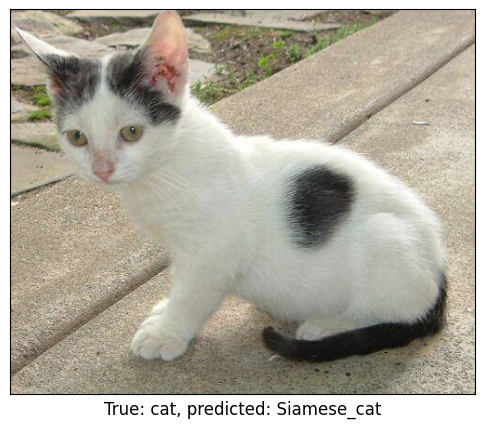

In [ ]:
# Predict
with torch.no_grad():
    model.eval()  # Set model to evaluation mode
    preds = model(image)
# decode the results into a list of tuples (class, description, probability)
# (one such list for each sample in the batch)
print('Predicted:', predict(preds, top=3))
plt.imshow(image_np)
plt.xlabel("True: cat, predicted: {}".format(predict(preds, top=3)[0][0]), fontsize= 12)
plt.xticks([])
plt.yticks([])
plt.grid(False)

The following function helps us to visualize the feature maps at a given layer of a given input image.

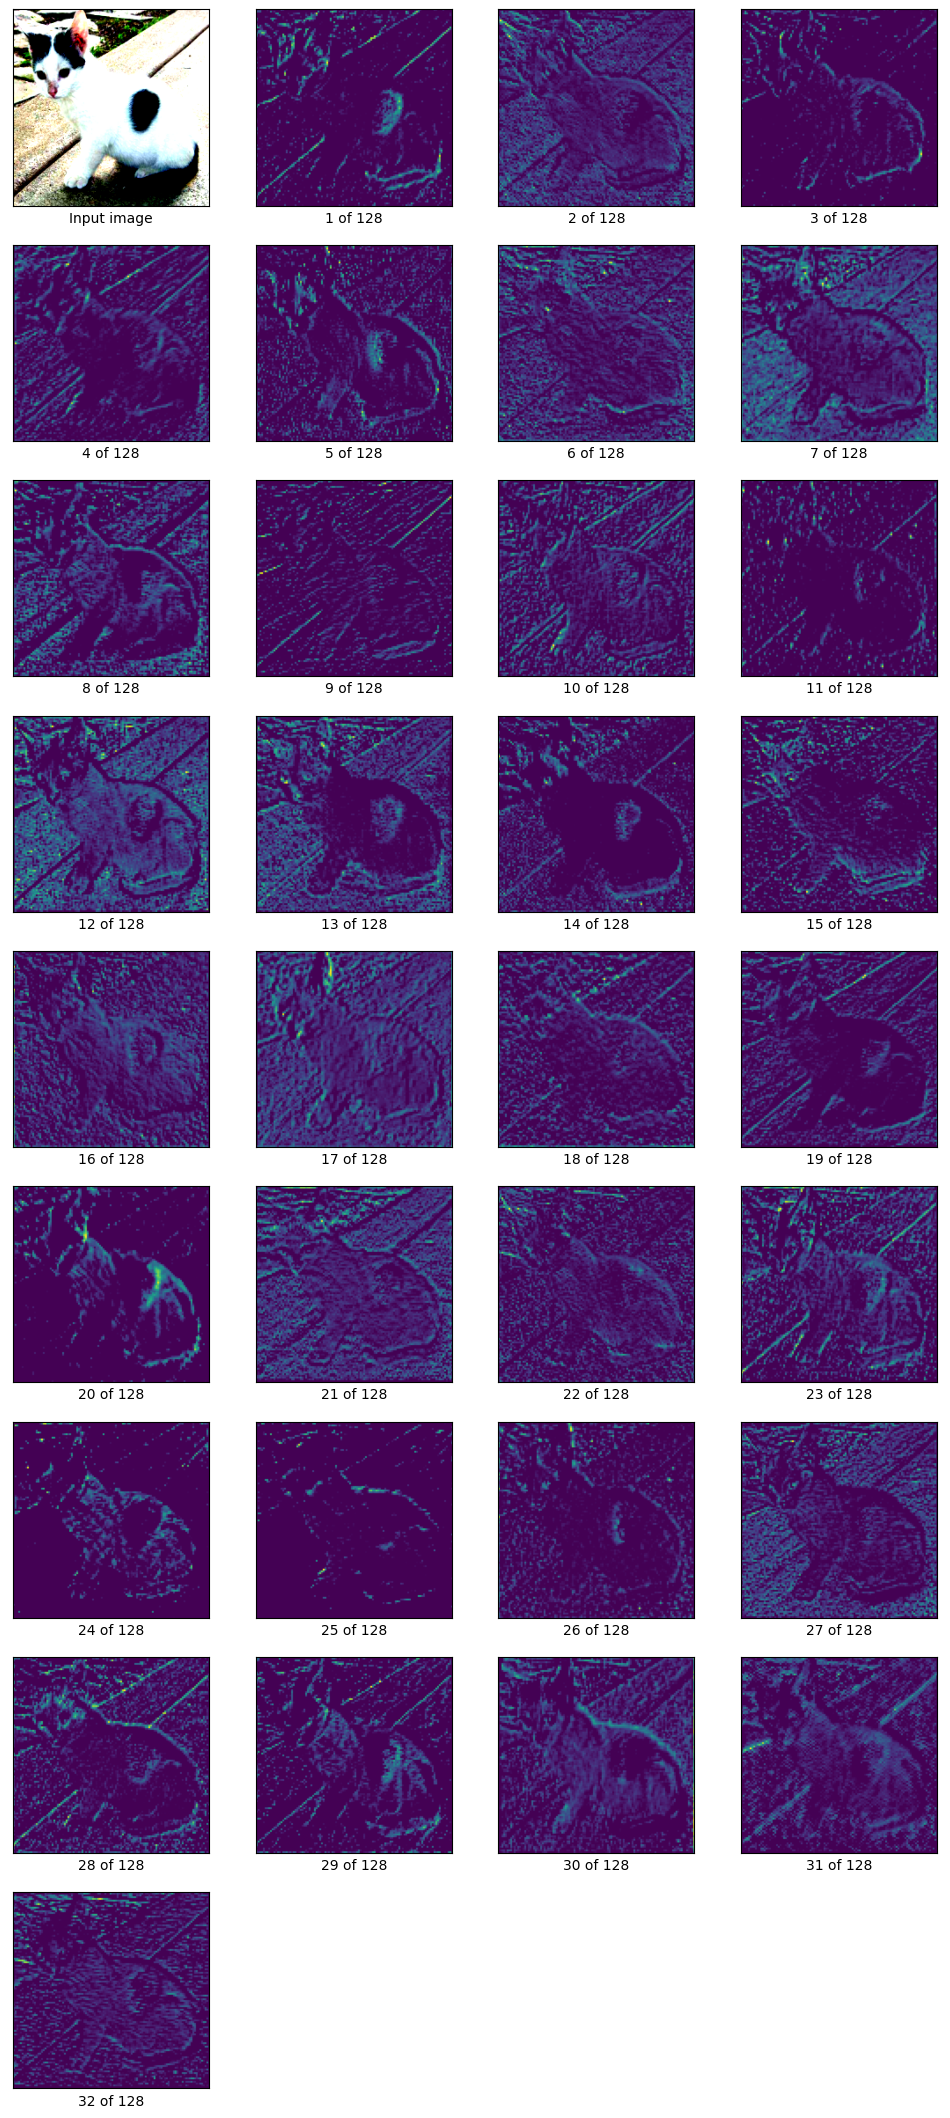

In [ ]:
def visualize_feature_maps(image=None, model=None, layer_to_visualize=None, n_cols=8):
    modulelist = list(model.features.modules())
    if layer_to_visualize < 0:
        layer_to_visualize += len(modulelist)
    # Forward pass to get the features
    output = None
    name = None
    input_img = image
    for count, layer in enumerate(modulelist[1:]):
        image = layer(image)
        if count == layer_to_visualize:
            output = image
            name = str(layer)
    filters = []
    output = output.data.squeeze()
    for i in range(output.shape[0]):
        filters.append(output[i,:,:])

    n_feature_maps = len(filters)  # get num_feature_maps
    n_images = math.floor(n_feature_maps/4) + 1  # display num_feature_maps/4 feature maps and original images
    n_rows = math.ceil(n_images/n_cols)
    fig = plt.figure(figsize=(n_cols * 3, n_rows * 3))
    plt.axis("off")
    for i in range(n_images):
        plt.subplot(n_rows, n_cols, i + 1)
        img = np.transpose(input_img.squeeze().cpu().numpy(), (1, 2, 0)) if i == 0 else filters[i].cpu().numpy()
        label = "Input image" if i == 0 else "{} of {}".format(i, n_feature_maps)
        plt.imshow(img)
        plt.xlabel(label, fontsize=10)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
    plt.show()
visualize_feature_maps(image=image, model=model, layer_to_visualize=5, n_cols=4)

As you can observe, it seems that each feature map preserves some characteristic features in the input image. You can do further investigations by visualizing feature maps of low-level, mid-level, and high-level feature maps and draw your own conclusions.

Visualize output of various layers

In [ ]:
# visulaize
def layer_outputs(model, image):
    modulelist = list(model.features.modules())
    outputs = []
    names = []
    for layer in modulelist[1:]:
        image = layer(image)
        outputs.append(image)
        names.append(str(layer))

    output_im = []
    for i in outputs:
        i = i.squeeze(0)
        temp = to_grayscale(i)
        output_im.append(temp.data.cpu().numpy())

    fig = plt.figure()
    plt.rcParams["figure.figsize"] = (30, 50)

    n_column = int(len(output_im)/4) + 1
    for i in range(len(output_im)):
        a = fig.add_subplot(n_column,4,i+1)
        imgplot = plt.imshow(output_im[i])
        plt.axis('off')
        a.set_title(names[i].partition('(')[0], fontsize=30)

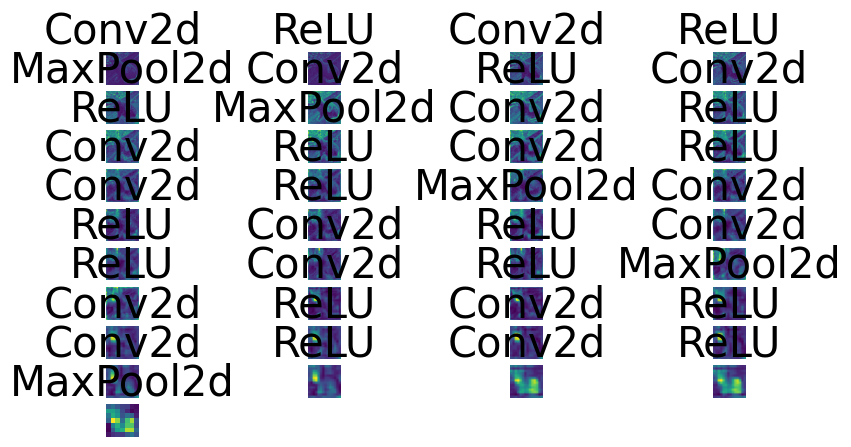

In [ ]:
layer_outputs(model=model, image=image) # If an error occurs, please run the cell twice.

Visualize filters of CONV2D layer of model

The following function supports us in visualizing the raw filters in a Conv2D layer in a CNN.

Here we visualize all filters of the first CONV2D layer of VGG19.

In [ ]:
def visualize_filter(model, layer_name=None, n_cols=8):
    # Find the specified layer in the model
    layer = None
    for name, module in model.named_modules():
        if name == layer_name:
            layer = module
            break
    assert isinstance(layer, torch.nn.Conv2d), "The current layer is not a Conv2D layer"
    filters = layer.weight.data.cpu().numpy()  # 4D tensor of all filters [num_filters, fil_depth, fil_height, fil_width]
    n_filters = filters.shape[0]  # get the number of filters to later visualize each of them
    n_rows = math.ceil(n_filters / n_cols)
    fig = plt.figure(figsize=(n_cols, n_rows))
    plt.axis("off")

    for i in range(n_filters):
        plt.subplot(n_rows, n_cols, i + 1)
        filter_img = filters[i, :, :, :]  # get the i-th filter
        # normalize the filter values to 0-1 range for display
        filter_img = (filter_img - filter_img.min()) / (filter_img.max() - filter_img.min())
        # rearrange the filter dimensions for visualization
        if filter_img.shape[0] == 3:  # if the filter has 3 channels (RGB)
            filter_img = np.transpose(filter_img, (1, 2, 0))
        plt.imshow(filter_img)
        plt.xlabel(f"Filter {i}")
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
    fig.tight_layout()
    plt.show()

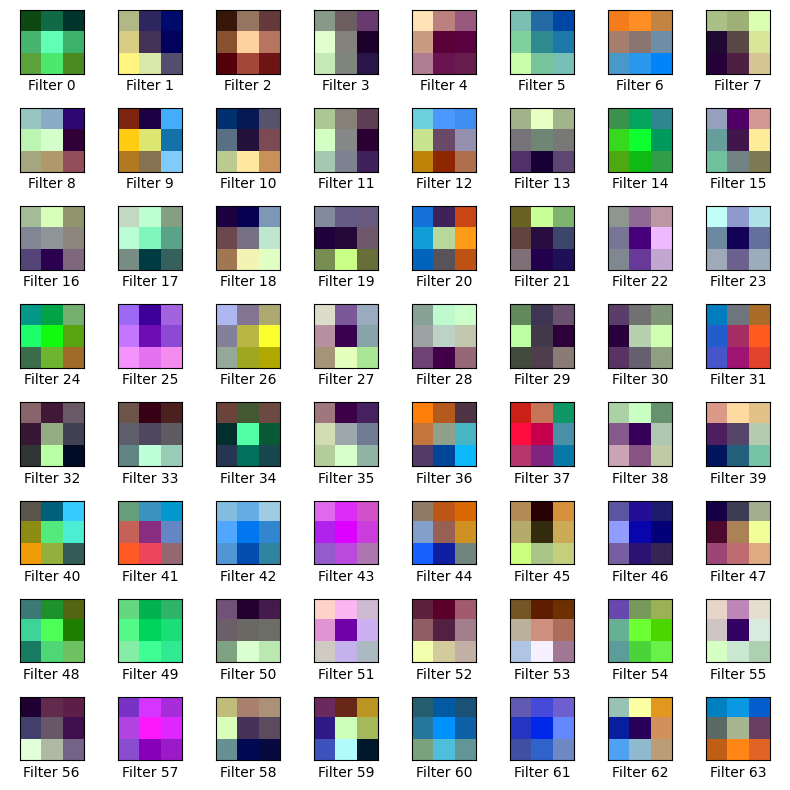

In [ ]:
# Visualize filters of a specific convolutional layer, e.g., 'features.0' for the first Conv2d layer
visualize_filter(model=model, layer_name='features.0', n_cols=8)

For higher layers, it is hard to base on the raw filters to justify what was learned at a Conv2D layer. The reason is that those filters are tiny filters of the shape $[3 \times 3]$. To obtain a better and meaningful visualization, we need to invoke the `activation maximization` technique which will be presented in the following part.

## <font color="#0b486b">II. Visualize CNN with Activation Maps</font> ##

The core idea of the activation maximization technique for visualizing a specific filter at a Conv2D layer is to choose the input image that can maximize the feature (activation) map corresponding to the filter.
- We initialize the input image randomly.
- We feed the input image to a CNN and consider the activation (feature) map corresponding to the filter we need to visualize.
- We take the average of neurons on this feature (activation) map and update the input image using gradient descent for maximizing that average.

The following code shows how to initialize the input image.

In [ ]:
def initialize_image(img_width, img_height):
    # Start from a gray image with some random noise
    img = torch.normal(mean=0.5, std=0.05, size=(1, 3, img_height, img_width))
    img = img.clamp(0, 1)  # Ensure the values are within the range [0, 1]
    img = img.to(device)
    return img

In what follows, we use gradient descent to update the input image in many iterations. Note that as specified in the following section, we define the loss function as the sum of the negative average neurons and the sparsity term on the input image. By this means, we desire to find the sparse input image that can activate the filter of interest, meaning that finding the patterns that can activate the corresponding filter.

In [ ]:
class_index = json.load(open('labels/imagenet_class_index.json'))
import torch.nn.functional as F
# Function to visualize the filter activation
def visualize_activation_maximization(model, layer_name='None', filter_index=50, iterations=50, learning_rate=10, alpha=10):
    cmap = np.zeros((224,224,3))
    mean = np.array([0.485, 0.456, 0.406])
    cmap += mean
    model = model.cuda()
    cmap = cmap.transpose(2,1,0)
    img = Variable(torch.Tensor(cmap).unsqueeze(0).cuda(), requires_grad=True)
   # print(img)
    for iteration in range(iterations):
        loss, img = gradient_descent_step(img, model, layer_name, filter_index, learning_rate, alpha)
    # # Decode the resulting input image
    cmap = img.data.squeeze()
    cmap.transpose_(0,1)
    cmap.transpose_(1,2)
    cmap = np.clip(np.array(deprocess(cmap).cpu()),0,255).astype('uint8')
    plt.figure(figsize=(5,5))
    plt.imshow(cmap)
    plt.axis('off')

We compute the loss as the negative average of the neurons over the feature map obtained by feeding the input image to the Conv2D layer.

In [ ]:
def compute_loss(img, model, layer_name, filter_index):
    activations = {}

    def hook_fn(module, input, output):
        activations[layer_name] = output

    # Register the hook
    hook = None
    for name, module in model.named_modules():
      #  print("name:", name)
        if name == layer_name:
            hook = module.register_forward_hook(hook_fn)
            break
    assert hook is not None, f"Layer {layer_name} not found in the model"
    # Forward pass
    model(img)
    hook.remove()
    # Loss function: maximize the activation of the specified filter
    activation = activations[layer_name]
    loss = -activation[0, filter_index].mean()
    return loss

We compute the regularization term as a norm over the input image to encourage sparse input images.

In [ ]:
# Function to compute the regularizer
def compute_regularizer(img, p=10):
    return torch.norm(img, p=p)

The following function assists us in computing the gradient of the loss function w.r.t the input image and updating the input image via gradient descent. Note that the final loss consists of two terms as aforementioned.

In [ ]:
# Function to perform a gradient descent step
def gradient_descent_step(img, model, layer_name, filter_index, learning_rate, alpha=10):
    model.zero_grad()
    loss = compute_loss(img, model, layer_name, filter_index) + alpha * compute_regularizer(img, p=10)
    loss.backward()
    with torch.no_grad():
        grads = img.grad.data  # Compute gradients
        grads = F.normalize(grads, p=2, dim=1)  # Normalize gradients
        img.data = img.data - learning_rate * grads
    #img.grad.zero_()
    return loss.item(), img

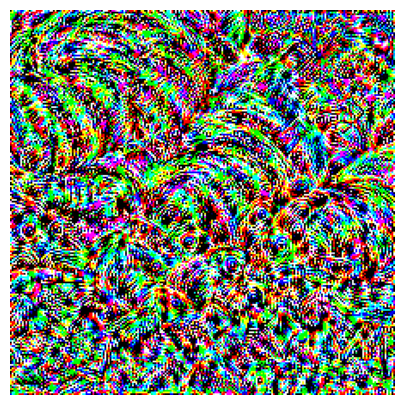

In [ ]:
# visualize activation maximization
visualize_activation_maximization(model, "features.34", learning_rate=50, filter_index=400, iterations=200, alpha=50)

**<font color="red">Exercise 1</font>**: Extend the following code to find the input image that can maximize the prediction of a given class. This input image can be regarded as a typical input image of that class.

*Hint: Consider the output layer to define the corresponding loss function.*

## <font color="#0b486b">III. Model Explanability with GradCam</font> ##

### <font color="#0b486b">III.1. Manual Implementation</font> ###

GradCam [this link](https://arxiv.org/pdf/1610.02391.pdf) is very interesting and simple model explanability technique that gives explanation about the part of an image that a CNN bases on to make prediction. In other words, it is an approach for model explainability which produces a heatmap of which regions of an image contributed strongly towards the final prediction.

In [ ]:
class _BaseWrapper(object):
    def __init__(self, model):
        super(_BaseWrapper, self).__init__()
        self.device = next(model.parameters()).device
        self.model = model
        self.handlers = []  # a set of hook function handlers

    def _encode_one_hot(self, ids):
        batch_size = ids.size(0)
        num_classes = self.logits.size(1)
        one_hot = torch.eye(num_classes, device=self.device)[ids].view(batch_size, num_classes)
        return one_hot

    def forward(self, image):
        self.image_shape = image.shape[2:]
        self.logits = self.model(image)
        self.probs = F.softmax(self.logits, dim=1)
        return self.probs.sort(dim=1, descending=True)  # ordered results

    def backward(self, ids):
        """
        Class-specific backpropagation
        """
        if isinstance(ids, int):
            ids = torch.tensor([[ids]], device=self.device)
        elif isinstance(ids, list):
            ids = torch.tensor(ids, device=self.device).unsqueeze(1)
        elif isinstance(ids, torch.Tensor) and ids.ndim == 1:
            ids = ids.unsqueeze(1)
        one_hot = self._encode_one_hot(ids)
        self.model.zero_grad()
        self.logits.backward(gradient=one_hot, retain_graph=True)

    def generate(self):
        raise NotImplementedError

    def remove_hook(self):
        """
        Remove all the forward/backward hook functions
        """
        for handle in self.handlers:
            handle.remove()


class BackPropagation(_BaseWrapper):
    def forward(self, image):
        self.image = image.requires_grad_()
        return super(BackPropagation, self).forward(self.image)

    def generate(self):
        gradient = self.image.grad.clone()
        self.image.grad.zero_()
        return gradient

class GradCAM_Base(_BaseWrapper):
    """
    "Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization"
    https://arxiv.org/pdf/1610.02391.pdf
    Look at Figure 2 on page 4
    """

    def __init__(self, model, candidate_layers=None):
        super(GradCAM_Base, self).__init__(model)
        self.fmap_pool = {}
        self.grad_pool = {}
        self.candidate_layers = candidate_layers  # list

        def save_fmaps(key):
            def forward_hook(module, input, output):
                self.fmap_pool[key] = output.detach()

            return forward_hook

        def save_grads(key):
            def backward_hook(module, grad_in, grad_out):
                self.grad_pool[key] = grad_out[0].detach()

            return backward_hook

        # If any candidates are not specified, the hook is registered to all the layers.
        for name, module in self.model.named_modules():
            if self.candidate_layers is None or name in self.candidate_layers:
                self.handlers.append(module.register_forward_hook(save_fmaps(name)))
                self.handlers.append(module.register_backward_hook(save_grads(name)))

    def _find(self, pool, target_layer):
        if target_layer in pool.keys():
            return pool[target_layer]
        else:
            raise ValueError(f"Invalid layer name: {target_layer}")

    def generate(self, target_layer):
        fmaps = self._find(self.fmap_pool, target_layer)
        grads = self._find(self.grad_pool, target_layer)
        weights = F.adaptive_avg_pool2d(grads, 1)

        gcam = torch.mul(fmaps, weights).sum(dim=1, keepdim=True)
        gcam = F.relu(gcam)
        gcam = F.interpolate(
            gcam, self.image_shape, mode="bilinear", align_corners=False
        )

        B, C, H, W = gcam.shape
        gcam = gcam.view(B, -1)
        gcam -= gcam.min(dim=1, keepdim=True)[0]
        gcam /= gcam.max(dim=1, keepdim=True)[0]
        gcam = gcam.view(B, C, H, W)

        return gcam


class GuidedBackPropagation_Base(BackPropagation):
    """
    "Striving for Simplicity: the All Convolutional Net"
    https://arxiv.org/pdf/1412.6806.pdf
    Look at Figure 1 on page 8.
    """

    def __init__(self, model):
        super(GuidedBackPropagation_Base, self).__init__(model)

        def backward_hook(module, grad_in, grad_out):
            # Cut off negative gradients
            if isinstance(module, nn.ReLU):
                return (F.relu(grad_in[0]),)

        for module in self.model.named_modules():
            self.handlers.append(module[1].register_backward_hook(backward_hook))



def make_gradcam(input_tensor, model, target_layer, label_index = None):
    gcam = GradCAM_Base(model=model)
    _ = gcam.forward(input_tensor)
    gcam.backward(label_index)
    heatmap = gcam.generate(target_layer=target_layer)
    return heatmap[0,0]

def make_guided_backpropagration(input_tensor, model, label_index = None):
    gbp = GuidedBackPropagation_Base(model=model)
    _ = gbp.forward(input_tensor)
    bp = BackPropagation(model=model)
    probs, ids = bp.forward(input_tensor)
    if label_index is None:
        gbp.backward(ids=ids[:,[0]])
    else:
        gbp.backward(ids=label_index)
    guided_gradients = gbp.generate()
    return guided_gradients[0]

def save_gradient(gradient):
    gradient = gradient.cpu().numpy().transpose(1, 2, 0)
    gradient = gradient - np.mean(gradient)
    gradient = gradient / (np.std(gradient) + 1e-5)
    gradient = gradient * 0.1
    gradient = gradient + 0.5
    gradient = np.clip(gradient, 0, 1)
    return np.uint8(gradient * 255)

def save_gradcam(gcam, raw_image, paper_cmap=False):
    gcam = gcam.cpu().numpy()
    cmap = cm.jet_r(gcam)[..., :3] * 255.0
    if paper_cmap:
        alpha = gcam[..., None]
        gcam = alpha * cmap + (1 - alpha) * raw_image
    else:
        gcam = (cmap.astype(float) + raw_image.astype(float)) / 2
    return np.uint8(gcam)

In [ ]:
def make_gradcam(input_tensor, model, target_layer, label_index = None):
    gcam = GradCAM_Base(model=model)
    _ = gcam.forward(input_tensor)
    gcam.backward(label_index)
    heatmap = gcam.generate(target_layer=target_layer)
    return heatmap[0,0]

def make_guided_backpropagration(input_tensor, model, label_index = None):
    gbp = GuidedBackPropagation_Base(model=model)
    _ = gbp.forward(input_tensor)
    bp = BackPropagation(model=model)
    probs, ids = bp.forward(input_tensor)
    if label_index is None:
        gbp.backward(ids=ids[:,[0]])
    else:
        gbp.backward(ids=label_index)
    guided_gradients = gbp.generate()
    # if gradcam_img is not None:
    #     guided_gradients = guided_gradients[0].cpu()
    #     guided_gradcam = save_gradient(torch.mul(regions[0], guided_gradients))  # Guided Grad is the multiplication of grad_cam and guided_gradient_backpropagation
    #     return guided_gradients[0], guided_gradcam
    # else:
    return guided_gradients[0]

We now show grad cam.

In [ ]:
# =========================================================================
# prepare input and model
img = Image.open("./imgs/cat.jpg")
# = np.array(Image.open("./imgs/cat.jpg"))
raw_img = cv2.resize(np.array(img), (224, 224))
input_tensor = preprocess_input(img)
input_tensor = input_tensor.to(device)
model_resnet50 = models.resnet50(pretrained=True).eval()
model_resnet50 = model_resnet50.to(device)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 199MB/s]


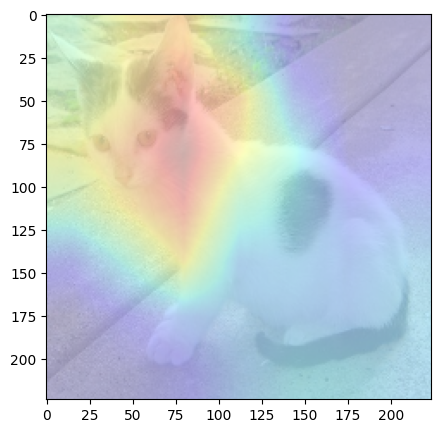

In [ ]:
heatmap = make_gradcam(input_tensor, model=model_resnet50,
                       target_layer="layer4", label_index = 285)
gradcam_img = save_gradcam(gcam=1 - heatmap, raw_image=raw_img, paper_cmap=False)
plt.rcParams['figure.figsize'] = [10, 5]
plt.imshow(gradcam_img,  alpha=0.5)

We show guided grad cam.

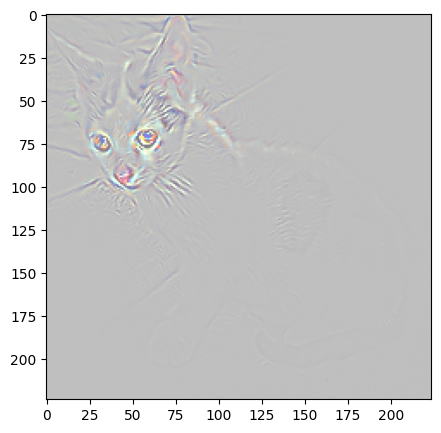

In [ ]:
guided_gradient = make_guided_backpropagration(input_tensor=input_tensor, model=model_resnet50, label_index = 285)

guided_gradcam = save_gradient(torch.mul(heatmap, guided_gradient))  # Guided Grad is the multiplication of grad_cam and guided_gradient_backpropagation

plt.rcParams['figure.figsize'] = [10, 5]
plt.imshow(guided_gradcam,  alpha=0.5)

In [ ]:
# test with other input tensor
img = Image.open("./imgs/dog-and-cat.jpg")
# = np.array(Image.open("./imgs/cat.jpg"))
raw_img = cv2.resize(np.array(img), (224, 224))
input_tensor = preprocess_input(img)
input_tensor = input_tensor.to(device)

We generate class activation heatmap for "dogsled," the class index is 537

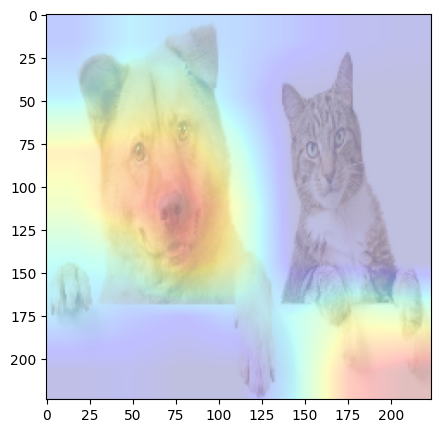

In [ ]:
heatmap = make_gradcam(input_tensor, model=model_resnet50, target_layer="layer4", label_index = 537)
gradcam_img = save_gradcam(gcam=1 - heatmap, raw_image=raw_img, paper_cmap=False)
plt.rcParams['figure.figsize'] = [10, 5]
plt.imshow(gradcam_img,  alpha=0.5)

### <font color="#0b486b">III.2. Using pytorch-grad-cam</font> ###

## Installing pytorch-grad-cam

`pytorch-grad-cam` can be installed by `pip` as follow:


In [ ]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=233a550d8d5e2f1a52d3d607784da9dddb618643ad5268a2db4394d977da7c1c
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam


We import neccesary functions of `pytorch-grad-cam` to invoke the gradient class activation map technique

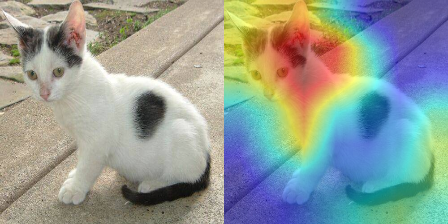

In [ ]:
import warnings
warnings.filterwarnings('ignore')
from torchvision import models
import numpy as np
import cv2
import requests
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam import GuidedBackpropReLUModel
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image, \
    deprocess_image, \
    preprocess_image
from PIL import Image

img = np.array(Image.open("./imgs/cat.jpg"))
img = cv2.resize(img, (224, 224))
img = np.float32(img) / 255
input_tensor = preprocess_image(img, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
model_resnet50 = models.resnet50(pretrained=True)
model_resnet50.eval()

# The target for the CAM is the Bear category.
# As usual for classication, the target is the logit output
# before softmax, for that category.
targets = [ClassifierOutputTarget(284)]
target_layers = [model_resnet50.layer4]
with GradCAM(model=model_resnet50, target_layers=target_layers) as cam:
    grayscale_cams = cam(input_tensor=input_tensor, targets=targets)
    cam_image = show_cam_on_image(img, grayscale_cams[0, :], use_rgb=True)
cam = np.uint8(255*grayscale_cams[0, :])
cam = cv2.merge([cam, cam, cam])
images = np.hstack((np.uint8(255*img), cam_image))
Image.fromarray(images)

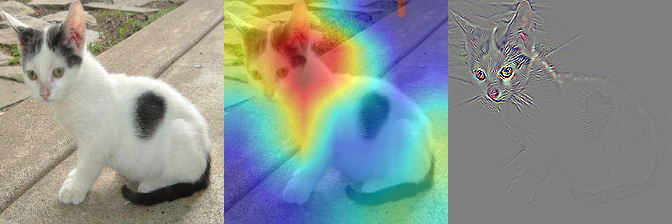

In [ ]:
targets = None
cam_algorithm = GradCAM
targets = [ClassifierOutputTarget(284)]
target_layers = [model_resnet50.layer4]
with cam_algorithm(model=model_resnet50, target_layers=target_layers) as cam:
    grayscale_cam = cam(input_tensor=input_tensor,
                    targets=targets,
                    aug_smooth=False,
                    eigen_smooth=False)
    grayscale_cam = grayscale_cam[0, :]
gb_model = GuidedBackpropReLUModel(model=model_resnet50, device=device)
gb = gb_model(input_tensor, target_category=284)

cam_mask = cv2.merge([grayscale_cam, grayscale_cam, grayscale_cam])

cam = np.uint8(255*grayscale_cam)
cam_merge = cv2.merge([cam, cam, cam])
gradCam = show_cam_on_image(img, cam_merge, use_rgb=False)
guided_backprop = deprocess_image(gb)
guided_gradcam = deprocess_image(cam_mask * gb)
images = np.hstack((np.uint8(255*img), gradCam, guided_gradcam))
Image.fromarray(images)

---
### <font color="#0b486b"> <div  style="text-align:center">**THE END**</div> </font>